# Galeria de gráficos do projeto

Este notebook exibe as figuras produzidas pela EDA e pela avaliação do modelo. Rode `python -m src.eda` e `python -m src.models.train` para regenerá-las.

Os gráficos ficam em `reports/figures/`; cada seção inclui a imagem e uma breve descrição.

In [ ]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'reports').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
FIGURES = ROOT / 'reports' / 'figures'
def show_figure(filename, title, description):
    path = FIGURES / filename
    display(Markdown(f'### {title}\n\n{description}'))
    if path.exists():
        display(Image(filename=str(path)))
    else:
        print(f'Figura ainda não gerada: {path}. Rode a etapa indicada no README.')

# Gera e exibe a correlação nesta célula do notebook, sem depender de imagem prévia.
from src.data.loader import load_dataset
from src.features.engineering import target_correlations, LOW_CORRELATION_THRESHOLD

df = load_dataset()
X = df.drop(columns=['stroke', 'id'], errors='ignore')
correlations = target_correlations(X, df['stroke'])
colors = ['#d97941' if value < LOW_CORRELATION_THRESHOLD else '#4c78a8' for value in correlations.values]
fig, ax = plt.subplots(figsize=(10, max(5, 0.42 * len(correlations))))
bars = ax.barh(correlations.index[::-1], correlations.values[::-1], color=colors[::-1])
ax.set_xlim(0, 1)
ax.set_xticks([i / 10 for i in range(11)])
ax.set_xlabel('Correlação absoluta com stroke (0 a 1)')
ax.set_title('Correlação das variáveis com stroke')
ax.axvline(LOW_CORRELATION_THRESHOLD, color='#b22222', linestyle='--', label=f'Limite de remoção ({LOW_CORRELATION_THRESHOLD:.3f})')
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)


## Exploração dos dados

![Distribuição do target](../reports/figures/target_imbalance.png)

![Boxplots](../reports/figures/boxplots_numeric.png)

![Valores ausentes](../reports/figures/missing_values.png)


In [ ]:
show_figure('target_imbalance.png', 'Desbalanceamento do target', 'Contagem de exemplos sem AVC e com AVC no conjunto original.')
show_figure('boxplots_numeric.png', 'Boxplots das variáveis numéricas', 'Distribuições e valores extremos das variáveis numéricas; os pontos extremos são mantidos para inspeção.')
show_figure('missing_values.png', 'Valores ausentes', 'Quantidade de valores ausentes por coluna, antes da imputação do pipeline.')
show_figure('correlation_with_stroke.png', 'Correlação absoluta com stroke', 'Barras ordenadas por correlação absoluta; valores de 0 a 1. Laranja indica correlação abaixo de 0,10; essa linha é apenas referência visual e todas as variáveis continuam no treino.')

## Avaliação dos modelos

![Curva Precision-Recall e AUPRC](../reports/figures/precision_recall_curve.png)

![Curva ROC e ROC AUC](../reports/figures/roc_curve.png)

![Matriz de confusão com métricas](../reports/figures/confusion_matrix.png)

### Curva Precision–Recall (AUPRC)

Mostra precisão versus recall em diferentes thresholds. A linha de base corresponde à prevalência da classe positiva no holdout.

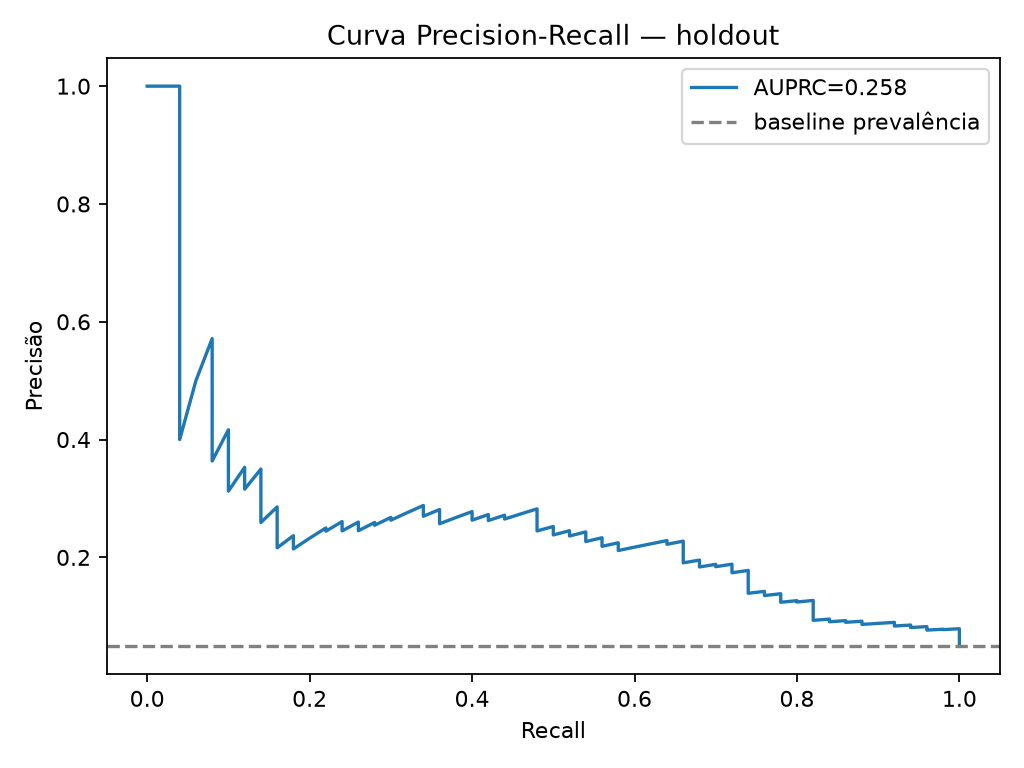

### Curva ROC (ROC AUC)

Mostra taxa de verdadeiros positivos versus taxa de falsos positivos ao variar o threshold.

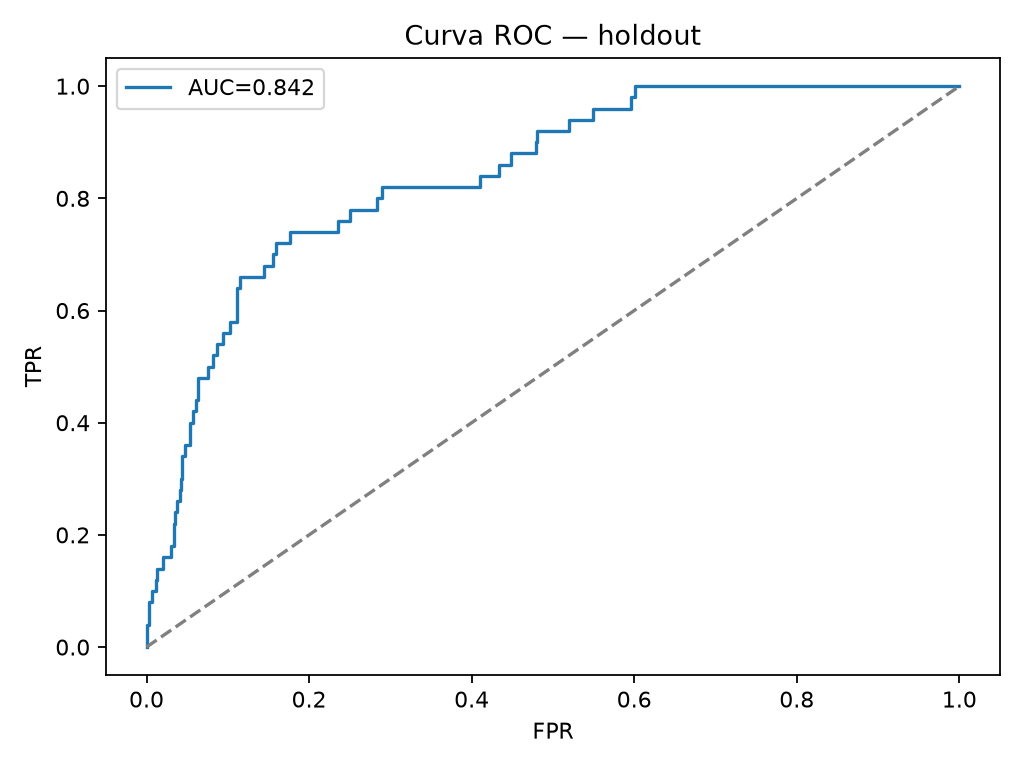

### Matriz de confusão e métricas

Contagens de acertos e erros no holdout, com F2/F1-score, accuracy, precision e recall do modelo selecionado. O threshold maximiza F2 para priorizar a classe AVC positiva.

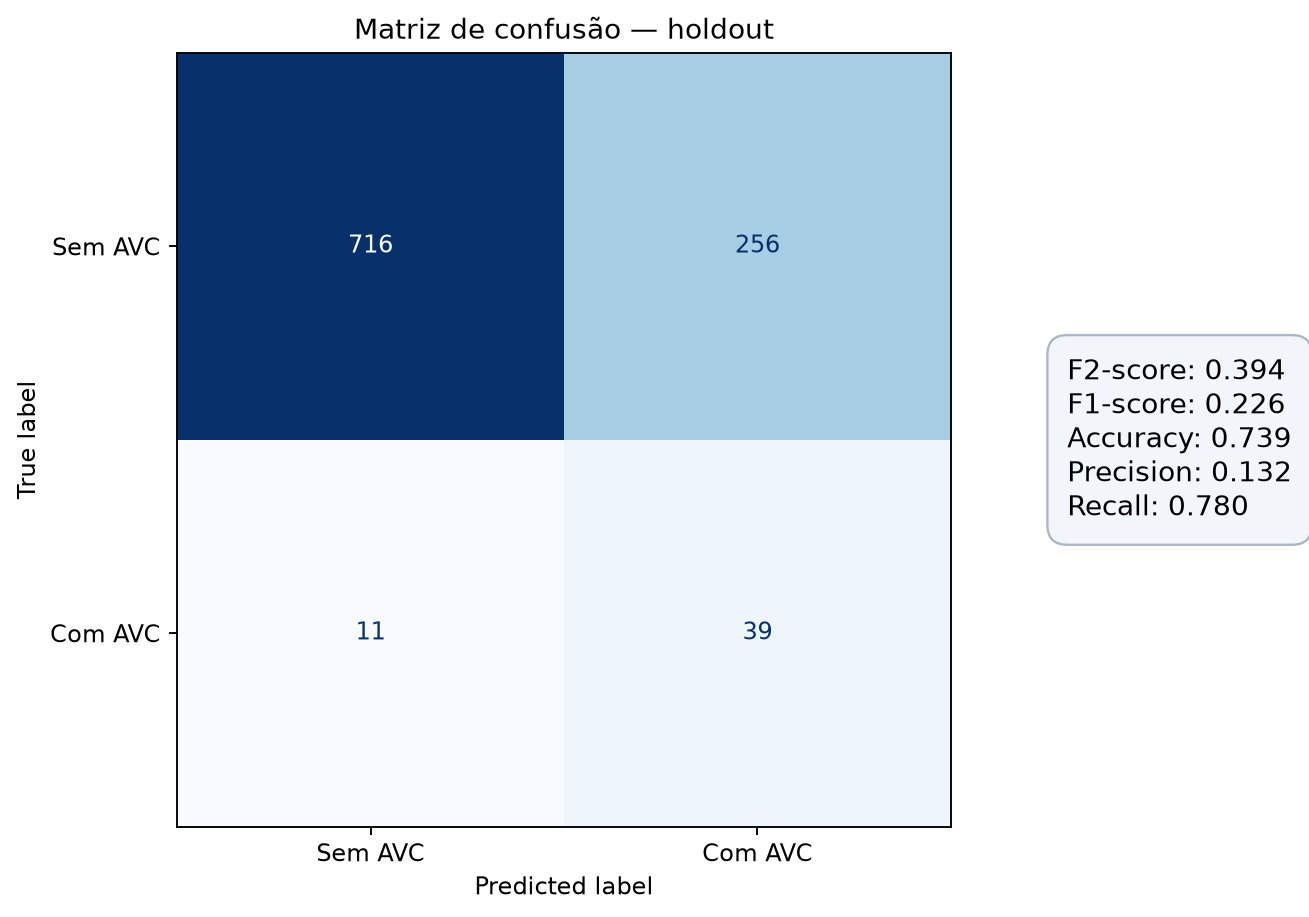

In [9]:
show_figure('precision_recall_curve.png', 'Curva Precision–Recall (AUPRC)', 'Mostra precisão versus recall em diferentes thresholds. A linha de base corresponde à prevalência da classe positiva no holdout.')
show_figure('roc_curve.png', 'Curva ROC (ROC AUC)', 'Mostra taxa de verdadeiros positivos versus taxa de falsos positivos ao variar o threshold.')
show_figure('confusion_matrix.png', 'Matriz de confusão e métricas', 'Contagens de acertos e erros no holdout, com F2/F1-score, accuracy, precision e recall do modelo selecionado. O threshold maximiza F2 para priorizar a classe AVC positiva.')

## Arquivos de saída

- `target_imbalance.png`, `boxplots_numeric.png`, `missing_values.png` e `correlation_with_stroke.png`: EDA.
- `precision_recall_curve.png`, `roc_curve.png` e `confusion_matrix.png`: avaliação do holdout.

AUPRC é mais informativa que accuracy isolada neste conjunto desbalanceado. Consulte `02_metricas_modelos.ipynb` para a tabela numérica completa. O threshold foi atualizado para otimizar F2 e dar mais peso ao recall da classe `stroke=1`.